# T04 — Pipeline reproducible de preparación de datos
## Clasificación de comentarios tóxicos — Civil Comments

**Objetivo:** preparar datos para un futuro clasificador binario de comentarios tóxicos y no tóxicos. Esta actividad se centra en calidad, limpieza, partición, transformación, controles y reproducibilidad; no exige entrenar un modelo ni presentar métricas predictivas.

**Relación con el trabajo integrador:** el proyecto busca identificar automáticamente comentarios potencialmente tóxicos a partir de su texto. Civil Comments contiene comentarios en línea con puntuaciones de toxicidad, por lo que es pertinente para construir y comprobar un pipeline de preparación de texto. El dataset está principalmente en inglés, limitación que debe considerarse si el sistema final se utilizará con comentarios en español.

**Integrantes:Branco Merino y Matías Díaz**

**Paralelo:** D03.

## Origen, identificación y carga de los datos

- **Dataset:** Civil Comments.
- **Repositorio:** https://huggingface.co/datasets/google/civil_comments
- **Configuración/split utilizado:** `train` del dataset publicado en Hugging Face.
- **Fecha de acceso:** se registra automáticamente al ejecutar.
- **Muestra:** hasta 50.000 filas seleccionadas de forma reproducible con semilla 42.
- **Identificación de versión:** el código registra la configuración utilizada, pero la versión puede cambiar si el repositorio remoto se actualiza. Para máxima reproducibilidad, se debe fijar una revisión/commit concreto del repositorio y registrar su identificador aquí cuando se confirme.

Se usa únicamente el split `train` de origen y se crea una partición interna de entrenamiento/prueba para esta actividad. No se mezclan los splits oficiales `validation` o `test`.

# 1 - Importar datos

In [2]:
!pip -q install datasets pandas scikit-learn matplotlib

from datasets import load_dataset
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
from datetime import datetime, timezone
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

SEMILLA = 42
N_MUESTRA = 50000
UMBRAL_TOXICIDAD = 0.5

random.seed(SEMILLA)
np.random.seed(SEMILLA)

URL_DATASET = "https://huggingface.co/datasets/google/civil_comments"
FECHA_ACCESO = datetime.now().astimezone().isoformat(timespec="seconds")

dataset = load_dataset("google/civil_comments", split="train")
N = min(N_MUESTRA, len(dataset))
df = dataset.shuffle(seed=SEMILLA).select(range(N)).to_pandas()

print("Dataset:", "google/civil_comments")
print("URL:", URL_DATASET)
print("Split de origen: train")
print("Fecha/hora de acceso:", FECHA_ACCESO)
print("Semilla:", SEMILLA)
print("Filas cargadas:", len(df))
print("Columnas:", df.columns.tolist())
display(df.head())

README.md:   0%|          | 0.00/7.73k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

... (4 outputs left out)

Generating validation split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Dataset: google/civil_comments
URL: https://huggingface.co/datasets/google/civil_comments
Split de origen: train
Fecha/hora de acceso: 2026-10-23T13:33:16+00:00
Semilla: 42
Filas cargadas: 50000
Columnas: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']


,text,toxicity,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
0,Socialists? What the hell does that have to do...,0.300000,0.000000,0.300000,0.0,0.200000,0.0,0.0
1,And I always thought that Eric Trump was the d...,0.808824,0.029412,0.088235,0.0,0.794118,0.0,0.0
2,I’m disappointed there’s no report from CB on ...,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0
3,Nothing like subsidizing a country that is thr...,0.166667,0.000000,0.000000,0.0,0.166667,0.0,0.0
4,The only way to save the rhino is to legalize ...,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0


# 2 - Diagnostico de calidad
Se inspeccionan dimensiones, tipos de datos, valores faltantes, textos vacíos, duplicados y rango de la puntuación toxicity. Esta variable es una puntuación entre 0 y 1; para plantear un problema de clasificación se transformará en una etiqueta binaria en una etapa explícita.

In [3]:
print("Dimensiones:", df.shape)
print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo"))
print("\nValores faltantes por columna:")
display(df.isna().sum().to_frame("faltantes"))

textos = df["text"].astype("string")
print("\nTextos faltantes:", df["text"].isna().sum())
print("Textos vacíos o solo espacios:", textos.fillna("").str.strip().eq("").sum())
print("Filas duplicadas exactas:", df.duplicated().sum())
print("Textos repetidos:", textos.duplicated().sum())

tox = pd.to_numeric(df["toxicity"], errors="coerce")
print("Puntuaciones toxicity faltantes/no numéricas:", tox.isna().sum())
print("Puntuaciones fuera del rango [0, 1]:", ((tox < 0) | (tox > 1)).sum())
display(tox.describe().to_frame("toxicity"))

Dimensiones: (50000, 8)

Tipos de datos:


,tipo
text,object
toxicity,float32
severe_toxicity,float32
obscene,float32
threat,float32
insult,float32
identity_attack,float32
sexual_explicit,float32



Valores faltantes por columna:


,faltantes
text,0
toxicity,0
severe_toxicity,0
obscene,0
threat,0
insult,0
identity_attack,0
sexual_explicit,0



Textos faltantes: 0
Textos vacíos o solo espacios: 0
Filas duplicadas exactas: 66
Textos repetidos: 75
Puntuaciones toxicity faltantes/no numéricas: 0
Puntuaciones fuera del rango [0, 1]: 0


,toxicity
count,50000.000000
mean,0.103082
std,0.196047
min,0.000000
25%,0.000000
50%,0.000000
75%,0.166667
max,1.000000


# 3 - Visualizar puntuaciones

Esto permite identificar si predominan los comentarios con puntuaciones bajas o si existe una distribución más equilibrada.

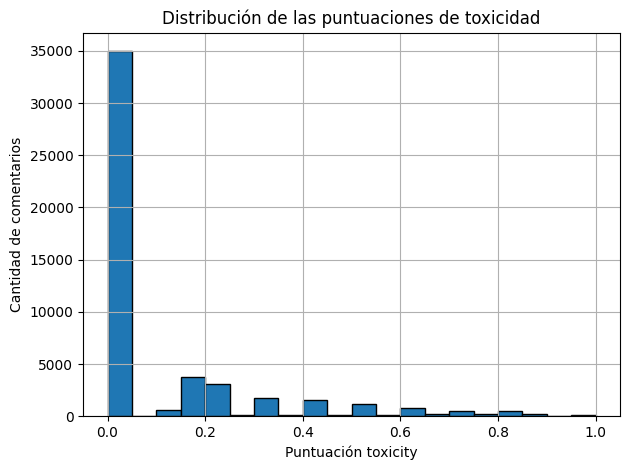

In [4]:
df["toxicity"].hist(bins=20, edgecolor="black")
plt.title("Distribución de las puntuaciones de toxicidad")
plt.xlabel("Puntuación toxicity")
plt.ylabel("Cantidad de comentarios")
plt.tight_layout()
plt.show()

**Análisis exploratorio del dataset Civil Comments
Dimensiones: 50.000 filas y 8 columnas.**

Tipos de datos: una columna de texto (text) y siete columnas numéricas con puntuaciones de toxicidad.

Valores faltantes: no se encontraron valores faltantes.

Duplicados exactos: se detectaron 66 registros duplicados, que deben revisarse antes de eliminarlos.

Textos vacíos: no se encontraron textos vacíos.

Estadísticas de toxicidad:
* Media: 0,103082.
* Desviación estándar: 0,196047.
* Mínimo: 0.
* Mediana: 0.
* Percentil 75: 0,166667.
* Máximo: 1.

**Conclusión**

El dataset presenta una buena integridad en cuanto a valores faltantes y textos vacíos. Las puntuaciones de toxicidad se concentran en valores bajos, aunque existen comentarios con puntuaciones elevadas. Se recomienda revisar los duplicados y visualizar la distribución de las puntuaciones antes de entrenar un modelo de detección de toxicidad.

# 4 - Limpiar los datos
Decisiones:
1. Quitar espacios al inicio y al final.
2. Eliminar textos faltantes o vacíos, porque no aportan contenido que pueda analizar un clasificador de texto.
3. Excluir puntuaciones `toxicity` faltantes o fuera de `[0, 1]`, ya que no permiten aplicar el umbral definido.
4. Para evitar que un mismo texto exacto aparezca en entrenamiento y prueba, conservar una sola fila por texto. Esta decisión puede descartar textos repetidos con puntuaciones diferentes; se informa cuántos se eliminan.
5. Crear la etiqueta `toxico`: `1` si `toxicity >= 0.5`, y `0` si `toxicity < 0.5`. El umbral es una decisión de este trabajo, no una etiqueta oficial.

La puntuación original se conserva para auditoría, pero no se usa como entrada del modelo: la única entrada será el texto.

In [5]:
filas_iniciales = len(df)
df_limpio = df.copy()
df_limpio["text"] = df_limpio["text"].astype("string").str.strip()
df_limpio["toxicity"] = pd.to_numeric(df_limpio["toxicity"], errors="coerce")

antes_texto = len(df_limpio)
df_limpio = df_limpio[
    df_limpio["text"].notna()
    & df_limpio["text"].ne("")
].copy()
eliminadas_texto = antes_texto - len(df_limpio)

antes_tox = len(df_limpio)
df_limpio = df_limpio[
    df_limpio["toxicity"].notna()
    & df_limpio["toxicity"].between(0, 1)
].copy()
eliminadas_toxicidad = antes_tox - len(df_limpio)

# Conteo de textos que aparecen más de una vez antes de deduplicar
textos_repetidos_eliminados = int(df_limpio["text"].duplicated(keep="first").sum())
df_pipeline = df_limpio.drop_duplicates(subset=["text"], keep="first").copy()

df_pipeline["toxico"] = (df_pipeline["toxicity"] >= UMBRAL_TOXICIDAD).astype("int8")

print("Filas iniciales:", filas_iniciales)
print("Eliminadas por texto vacío/faltante:", eliminadas_texto)
print("Eliminadas por puntuación inválida:", eliminadas_toxicidad)
print("Textos repetidos eliminados (se conserva la primera aparición):", textos_repetidos_eliminados)
print("Filas finales:", len(df_pipeline))
print("\nDistribución de clases (0=no tóxico, 1=tóxico):")
display(df_pipeline["toxico"].value_counts().sort_index().rename(index={0:"No tóxico (0)",1:"Tóxico (1)"}).to_frame("cantidad"))
display((df_pipeline["toxico"].value_counts(normalize=True).sort_index()*100).round(2).rename(index={0:"No tóxico (0)",1:"Tóxico (1)"}).to_frame("porcentaje"))

assert df_pipeline["text"].notna().all()
assert df_pipeline["text"].str.strip().ne("").all()
assert df_pipeline["toxicity"].between(0, 1).all()
assert df_pipeline["text"].is_unique
assert set(df_pipeline["toxico"].unique()).issubset({0, 1})
print("Controles de limpieza y etiquetado superados.")

Filas iniciales: 50000
Eliminadas por texto vacío/faltante: 0
Eliminadas por puntuación inválida: 0
Textos repetidos eliminados (se conserva la primera aparición): 75
Filas finales: 49925

Distribución de clases (0=no tóxico, 1=tóxico):


,cantidad
toxico,
No tóxico (0),45977
Tóxico (1),3948


,porcentaje
toxico,
No tóxico (0),92.09
Tóxico (1),7.91


Controles de limpieza y etiquetado superados.


Justificación: un registro sin texto no permite analizar el contenido del mensaje. En cambio, los duplicados deben examinarse porque podrían ser legítimos o revelar problemas de recopilación.

# 5 - Seleccionar las variables y separar los datos
- **Entrada `X`:** columna `text`.
- **Objetivo `y`:** etiqueta binaria `toxico`.
- **Partición:** 80% entrenamiento y 20% prueba.
- **Estratificación:** se utiliza `stratify=y` para conservar aproximadamente la proporción de ambas clases en los dos conjuntos.
- **Control de fuga:** se elimina la repetición exacta de textos antes de la partición y se verifica que no haya intersección entre los textos de entrenamiento y prueba.

La partición aleatoria es adecuada como primera evaluación si los comentarios se consideran observaciones independientes. Si el caso real exige generalizar a usuarios, hilos o periodos futuros, sería preferible una partición por grupo o temporal; este dataset/muestra no se usa aquí para afirmar esa independencia.

In [6]:
X = df_pipeline["text"]
y = df_pipeline["toxico"]

from sklearn.model_selection import train_test_split
import numpy as np

# X contiene los textos e y las etiquetas binarias (0 = no tóxico, 1 = tóxico)

# Primera división: 70 % entrenamiento y 30 % temporal
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEMILLA,
    stratify=y
)

# Segunda división: repartir el 30 % restante en 15 % validación y 15 % prueba
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEMILLA,
    stratify=y_temp
)

# Mostrar cantidades y porcentajes
total = len(X)

print(f"Total de registros: {total}")
print(f"Train: {len(X_train)} ({len(X_train)/total:.2%})")
print(f"Validation: {len(X_val)} ({len(X_val)/total:.2%})")
print(f"Test: {len(X_test)} ({len(X_test)/total:.2%})")

print("\nDistribución de clases:")
print("Train:")
print(np.unique(y_train, return_counts=True))
print("Validation:")
print(np.unique(y_val, return_counts=True))
print("Test:")
print(np.unique(y_test, return_counts=True))

# 1. Verificar que no existan textos compartidos entre conjuntos
solapamiento_train_val = set(X_train).intersection(set(X_val))
solapamiento_train_test = set(X_train).intersection(set(X_test))
solapamiento_val_test = set(X_val).intersection(set(X_test))

print("Textos compartidos entre train y validation:",
      len(solapamiento_train_val))
print("Textos compartidos entre train y test:",
      len(solapamiento_train_test))
print("Textos compartidos entre validation y test:",
      len(solapamiento_val_test))

assert len(solapamiento_train_val) == 0
assert len(solapamiento_train_test) == 0
assert len(solapamiento_val_test) == 0

# 2. Verificar que estén presentes las dos clases en cada conjunto
assert set(np.unique(y_train)) == {0, 1}
assert set(np.unique(y_val)) == {0, 1}
assert set(np.unique(y_test)) == {0, 1}

# 3. Verificar los porcentajes de la partición
total = len(X)
print("Controles de partición superados.")

Total de registros: 49925
Train: 34947 (70.00%)
Validation: 7489 (15.00%)
Test: 7489 (15.00%)

Distribución de clases:
Train:
(array([0, 1], dtype=int8), array([32183,  2764]))
Validation:
(array([0, 1], dtype=int8), array([6897,  592]))
Test:
(array([0, 1], dtype=int8), array([6897,  592]))
Textos compartidos entre train y validation: 0
Textos compartidos entre train y test: 0
Textos compartidos entre validation y test: 0
Controles de partición superados.


## 6. Transformación de texto con TF-IDF

TF-IDF convierte el texto en una representación numérica. Se usa un máximo de 10.000 características y unigramas/bigramas. **El vectorizador se ajusta solo con `X_train`**; el conjunto de prueba se transforma con el vocabulario aprendido en entrenamiento. Así se evita que la prueba influya en el ajuste de la representación.

In [7]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Matriz TF-IDF entrenamiento:", X_train_tfidf.shape)
print("Matriz TF-IDF prueba:", X_test_tfidf.shape)
print("Vocabulario aprendido:", len(tfidf.vocabulary_))

assert X_train_tfidf.shape[1] == X_test_tfidf.shape[1]
assert X_train_tfidf.shape[0] == len(y_train)
assert X_test_tfidf.shape[0] == len(y_test)
print("Controles TF-IDF superados.")

Matriz TF-IDF entrenamiento: (34947, 10000)
Matriz TF-IDF prueba: (7489, 10000)
Vocabulario aprendido: 10000
Controles TF-IDF superados.


## 7 - Bitácora de decisiones y controles finales
La bitácora resume las decisiones principales, su justificación y la evidencia que se debe obtener al ejecutar el notebook. Las salidas numéricas se generan dinámicamente para que no dependan de resultados copiados manualmente.

In [8]:
bitacora = pd.DataFrame([
    {
        "decision": "Fuente y muestra",
        "justificacion": (
            "Civil Comments contiene comentarios anotados con puntuación "
            "de toxicidad; se limita a una muestra reproducible "
            "para facilitar la ejecución."
        ),
        "control": (
            f"{len(df)} filas; semilla {SEMILLA}; "
            f"fecha de acceso {FECHA_ACCESO}"
        )
    },
    {
        "decision": "Eliminar textos vacíos/faltantes",
        "justificacion": (
            "Un texto vacío no aporta información para clasificar "
            "el comentario."
        ),
        "control": f"{eliminadas_texto} filas eliminadas"
    },
    {
        "decision": "Excluir puntuaciones inválidas",
        "justificacion": (
            "No se puede derivar una etiqueta válida si toxicity falta "
            "o está fuera de [0, 1]."
        ),
        "control": f"{eliminadas_toxicidad} filas eliminadas"
    },
    {
        "decision": "Deduplicar por texto",
        "justificacion": (
            "Evitar que textos idénticos aparezcan en distintas "
            "particiones; se conserva la primera aparición."
        ),
        "control": (
            f"{textos_repetidos_eliminados} textos repetidos eliminados; "
            f"{len(df_pipeline)} filas finales"
        )
    },
    {
        "decision": "Umbral de clasificación",
        "justificacion": (
            f"Definir una etiqueta binaria reproducible: "
            f"toxicity >= {UMBRAL_TOXICIDAD} es tóxico; "
            "un valor inferior es no tóxico."
        ),
        "control": f"Clases: {y.value_counts().to_dict()}"
    },
    {
        "decision": "Separación estratificada 70/15/15",
        "justificacion": (
            "Separar entrenamiento, validación y prueba, conservando "
            "aproximadamente la proporción de las clases. "
            "Validación se utiliza para seleccionar modelos; "
            "prueba se reserva para la evaluación final."
        ),
        "control": (
            f"{len(X_train)} entrenamiento ({len(X_train)/len(X):.2%}); "
            f"{len(X_val)} validación ({len(X_val)/len(X):.2%}); "
            f"{len(X_test)} prueba ({len(X_test)/len(X):.2%})"
        )
    },
    {
        "decision": "Control de solapamiento",
        "justificacion": (
            "Comprobar que no haya textos idénticos compartidos "
            "entre entrenamiento, validación y prueba."
        ),
        "control": (
            f"Train-val: {len(set(X_train) & set(X_val))}; "
            f"train-test: {len(set(X_train) & set(X_test))}; "
            f"val-test: {len(set(X_val) & set(X_test))}"
        )
    },
    {
        "decision": "TF-IDF",
        "justificacion": (
            "Convertir el texto a características numéricas y ajustar "
            "el vocabulario exclusivamente con entrenamiento."
        ),
        "control": (
            f"{X_train_tfidf.shape[1]} características; "
            f"train {X_train_tfidf.shape}; "
            f"test {X_test_tfidf.shape}"
        )
    }
])

display(bitacora)

ruta_bitacora = "bitacora_pipeline.csv"
bitacora.to_csv(
    ruta_bitacora,
    index=False,
    encoding="utf-8-sig"
)

print("Bitácora guardada en:", ruta_bitacora)

# ============================================================
# CONTROLES FINALES
# ============================================================

# Cantidad total de registros
assert len(X_train) + len(X_val) + len(X_test) == len(df_pipeline)

# Verificar que las clases estén presentes en los tres conjuntos
assert set(np.unique(y_train)) == {0, 1}
assert set(np.unique(y_val)) == {0, 1}
assert set(np.unique(y_test)) == {0, 1}

# Verificar que no existan textos idénticos entre particiones
solapamiento_train_val = set(X_train) & set(X_val)
solapamiento_train_test = set(X_train) & set(X_test)
solapamiento_val_test = set(X_val) & set(X_test)

assert len(solapamiento_train_val) == 0
assert len(solapamiento_train_test) == 0
assert len(solapamiento_val_test) == 0

# Verificar las dimensiones de TF-IDF
assert X_train_tfidf.shape[0] == len(X_train)
assert X_test_tfidf.shape[0] == len(X_test)

# Verificar que la suma de las proporciones sea aproximadamente 100 %
total = len(X_train) + len(X_val) + len(X_test)

print("\nPorcentajes finales:")
print(f"Train:      {len(X_train)/total:.2%}")
print(f"Validation: {len(X_val)/total:.2%}")
print(f"Test:       {len(X_test)/total:.2%}")

print("\nTODOS LOS CONTROLES FINALES SUPERADOS.")

,decision,justificacion,control
0,Fuente y muestra,Civil Comments contiene comentarios anotados c...,50000 filas; semilla 42; fecha de acceso 2026-...
1,Eliminar textos vacíos/faltantes,Un texto vacío no aporta información para clas...,0 filas eliminadas
2,Excluir puntuaciones inválidas,No se puede derivar una etiqueta válida si tox...,0 filas eliminadas
3,Deduplicar por texto,Evitar que textos idénticos aparezcan en disti...,75 textos repetidos eliminados; 49925 filas fi...
4,Umbral de clasificación,Definir una etiqueta binaria reproducible: tox...,"Clases: {0: 45977, 1: 3948}"
5,Separación estratificada 70/15/15,"Separar entrenamiento, validación y prueba, co...",34947 entrenamiento (70.00%); 7489 validación ...
6,Control de solapamiento,Comprobar que no haya textos idénticos compart...,Train-val: 0; train-test: 0; val-test: 0
7,TF-IDF,Convertir el texto a características numéricas...,"10000 características; train (34947, 10000); t..."


Bitácora guardada en: bitacora_pipeline.csv

Porcentajes finales:
Train:      70.00%
Validation: 15.00%
Test:       15.00%

TODOS LOS CONTROLES FINALES SUPERADOS.


## 8. Limitaciones y conclusión

**Limitaciones:** (1) la etiqueta binaria depende del umbral elegido y simplifica una puntuación continua; comentarios cercanos al umbral pueden ser ambiguos. (2) Civil Comments está principalmente en inglés, por lo que su utilidad puede ser limitada para clasificar comentarios en español o en el contexto chileno. (3) eliminar textos repetidos conservando la primera aparición puede descartar anotaciones diferentes del mismo texto. (4) la partición aleatoria no garantiza generalización a usuarios, conversaciones o periodos nuevos.

**Conclusión:** el pipeline documenta el origen de los datos, diagnostica su calidad, aplica limpieza justificada, define explícitamente la etiqueta de clasificación, separa entrenamiento/prueba con estratificación y transforma el texto con TF-IDF sin ajustar sobre la prueba. No se entrena un modelo ni se reportan métricas predictivas porque no son requisitos de esta actividad.

**Uso de IA generativa:** Se utilizó ChatGPT como apoyo para estructurar, programar, revisar el pipeline y las explicaciones finales. El equipo revisó las decisiones, ejecutó el notebook y es responsable del contenido final.

## Regresión Logística + TF-IDF

C=0.1 | F1 macro validation=0.6591
C=1.0 | F1 macro validation=0.6890
C=10.0 | F1 macro validation=0.6881

Mejores parámetros: {'C': 1.0}
Mejor F1 macro en validation: 0.6890

RESULTADOS FINALES: REGRESIÓN LOGÍSTICA + TF-IDF

              precision    recall  f1-score   support

   No tóxico       0.97      0.91      0.94      6897
      Tóxico       0.38      0.64      0.48       592

    accuracy                           0.89      7489
   macro avg       0.67      0.78      0.71      7489
weighted avg       0.92      0.89      0.90      7489



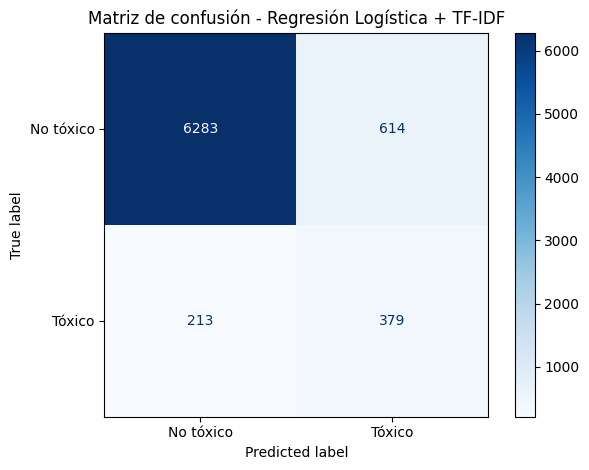

In [ ]:

# ============================================================
# MODELO 1: REGRESIÓN LOGÍSTICA + TF-IDF (UNIGRAMAS/BIGRAMAS)
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import ParameterGrid
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Crear TF-IDF usando SOLO el conjunto de entrenamiento
# ------------------------------------------------------------

vectorizador = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=10000,
    sublinear_tf=True
)

X_train_tfidf = vectorizador.fit_transform(X_train)
X_val_tfidf = vectorizador.transform(X_val)
X_test_tfidf = vectorizador.transform(X_test)

# ------------------------------------------------------------
# 2. Entrenar y seleccionar usando VALIDATION
# ------------------------------------------------------------

mejor_f1_val = -1
mejores_parametros = None
modelo_lr = None

for C in [0.1, 1.0, 10.0]:
    candidato = LogisticRegression(
        C=C,
        max_iter=1000,
        class_weight="balanced",
        random_state=SEMILLA
    )

    candidato.fit(X_train_tfidf, y_train)

    pred_val = candidato.predict(X_val_tfidf)
    f1_val = f1_score(
        y_val, pred_val,
        average="macro",
        zero_division=0
    )

    print(f"C={C} | F1 macro validation={f1_val:.4f}")

    if f1_val > mejor_f1_val:
        mejor_f1_val = f1_val
        mejores_parametros = {"C": C}
        modelo_lr = candidato

print("\nMejores parámetros:", mejores_parametros)
print(f"Mejor F1 macro en validation: {mejor_f1_val:.4f}")

# ------------------------------------------------------------
# 3. Evaluación FINAL en TEST (una sola vez para reportar)
# ------------------------------------------------------------

y_pred_lr = modelo_lr.predict(X_test_tfidf)

metricas_lr = {
    "Modelo": "Regresión Logística + TF-IDF",
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision macro": precision_score(
        y_test, y_pred_lr,
        average="macro", zero_division=0
    ),
    "Recall macro": recall_score(
        y_test, y_pred_lr,
        average="macro", zero_division=0
    ),
    "F1 macro": f1_score(
        y_test, y_pred_lr,
        average="macro", zero_division=0
    ),
    "F1 tóxicos": f1_score(
        y_test, y_pred_lr,
        pos_label=1, zero_division=0
    )
}

print("\nRESULTADOS FINALES: REGRESIÓN LOGÍSTICA + TF-IDF\n")
print(classification_report(
    y_test,
    y_pred_lr,
    labels=[0, 1],
    target_names=["No tóxico", "Tóxico"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    labels=[0, 1],
    display_labels=["No tóxico", "Tóxico"],
    cmap="Blues"
)

plt.title("Matriz de confusión - Regresión Logística + TF-IDF")
plt.tight_layout()
plt.show()


### Instalar las librerías para BERT

In [ ]:
!pip -q install transformers accelerate

## Preparar BERT

In [ ]:
# ============================================================
# MODELO 2: BERT PARA CLASIFICACIÓN BINARIA
# ============================================================

import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback
)
from sklearn.model_selection import train_test_split

MODELO_BERT = "google-bert/bert-base-uncased"
MAX_LENGTH = 256

# Cargar el tokenizador

tokenizer = AutoTokenizer.from_pretrained(MODELO_BERT)

def crear_dataset(textos, etiquetas):
    return Dataset.from_dict({
        "text": list(textos),
        "labels": list(map(int, etiquetas))
    })

train_dataset = crear_dataset(X_train, y_train)
val_dataset = crear_dataset(X_val, y_val)
test_dataset = crear_dataset(X_test, y_test)

def tokenizar_lote(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

train_dataset = train_dataset.map(
    tokenizar_lote, batched=True
)
val_dataset = val_dataset.map(
    tokenizar_lote, batched=True
)
test_dataset = test_dataset.map(
    tokenizar_lote, batched=True
)

# Eliminar texto original: el modelo usa los tokens
train_dataset = train_dataset.remove_columns(["text"])
val_dataset = val_dataset.remove_columns(["text"])
test_dataset = test_dataset.remove_columns(["text"])

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Entrenamiento BERT:", len(train_dataset))
print("Validación BERT:", len(val_dataset))
print("Prueba final:", len(test_dataset))
print("GPU disponible:", torch.cuda.is_available())

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/34947 [00:00<?, ? examples/s]

Map:   0%|          | 0/7489 [00:00<?, ? examples/s]

Map:   0%|          | 0/7489 [00:00<?, ? examples/s]

Entrenamiento BERT: 34947
Validación BERT: 7489
Prueba final: 7489
GPU disponible: True


### Cargar y entrenar BERT

In [ ]:
modelo_bert = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BERT,
    num_labels=2,
    id2label={0: "No tóxico", 1: "Tóxico"},
    label2id={"No tóxico": 0, "Tóxico": 1}
)

def metricas_bert(eval_pred):
    logits, etiquetas = eval_pred
    predicciones = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(etiquetas, predicciones),
        "f1_macro": f1_score(
            etiquetas, predicciones,
            average="macro", zero_division=0
        ),
        "f1_toxicos": f1_score(
            etiquetas, predicciones,
            pos_label=1, zero_division=0
        )
    }

argumentos = TrainingArguments(
    output_dir="./bert_civil_comments",
    num_train_epochs=5,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=1,
    report_to="none",
    seed=SEMILLA,
    fp16=torch.cuda.is_available()
)

trainer = Trainer(
    model=modelo_bert,
    args=argumentos,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=metricas_bert,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
        ]
)

trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Toxicos
1,0.189900,0.180972,0.948725,0.798009,0.623529
2,0.150462,0.223960,0.935238,0.800307,0.636159
3,0.087157,0.278874,0.943250,0.810798,0.652494
4,0.036623,0.368759,0.950194,0.811804,0.650422
5,0.004310,0.461668,0.946455,0.815696,0.660457


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=21845, training_loss=0.09104936381558527, metrics={'train_runtime': 2211.698, 'train_samples_per_second': 79.005, 'train_steps_per_second': 9.877, 'total_flos': 1.512355562877384e+16, 'train_loss': 0.09104936381558527, 'epoch': 5.0})

### Evaluar BERT sobre el conjunto de prueba

RESULTADOS: BERT

              precision    recall  f1-score   support

   No tóxico       0.97      0.97      0.97      6897
      Tóxico       0.63      0.65      0.64       592

    accuracy                           0.94      7489
   macro avg       0.80      0.81      0.80      7489
weighted avg       0.94      0.94      0.94      7489



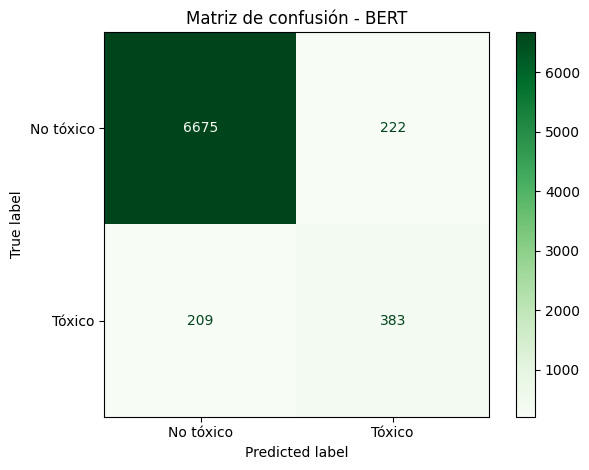

In [ ]:
predicciones_bert = trainer.predict(test_dataset)

y_pred_bert = np.argmax(
    predicciones_bert.predictions,
    axis=-1
)

metricas_bert_final = {
    "Modelo": "BERT",
    "Accuracy": accuracy_score(y_test, y_pred_bert),
    "Precision macro": precision_score(
        y_test, y_pred_bert,
        average="macro", zero_division=0
    ),
    "Recall macro": recall_score(
        y_test, y_pred_bert,
        average="macro", zero_division=0
    ),
    "F1 macro": f1_score(
        y_test, y_pred_bert,
        average="macro", zero_division=0
    ),
    "F1 tóxicos": f1_score(
        y_test, y_pred_bert,
        pos_label=1, zero_division=0
    )
}

print("RESULTADOS: BERT\n")
print(classification_report(
    y_test,
    y_pred_bert,
    labels=[0, 1],
    target_names=["No tóxico", "Tóxico"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_bert,
    labels=[0, 1],
    display_labels=["No tóxico", "Tóxico"],
    cmap="Greens"
)
plt.title("Matriz de confusión - BERT")
plt.tight_layout()
plt.show()

## Comparar los dos modelos

,Accuracy,Precision macro,Recall macro,F1 macro,F1 tóxicos
Modelo,,,,,
Regresión Logística + TF-IDF,0.8896,0.6744,0.7756,0.7082,0.4782
BERT,0.9424,0.8013,0.8074,0.8043,0.6399


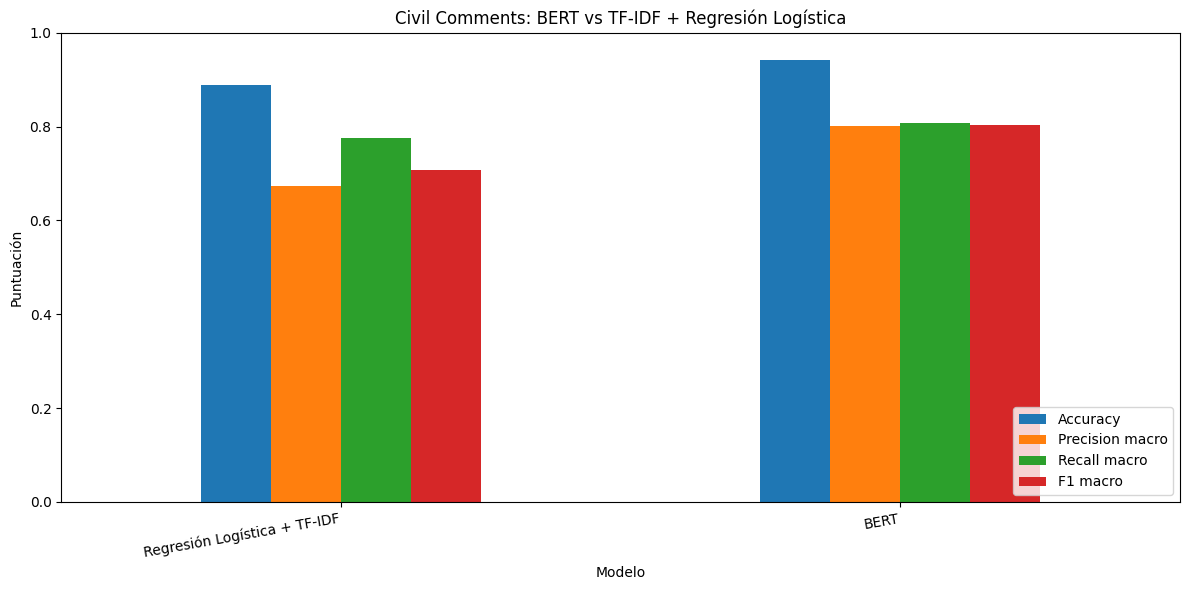

Mejor modelo según F1 macro: BERT
F1 macro obtenido: 0.8043


In [ ]:
# ============================================================
# COMPARACIÓN FINAL DE LOS MODELOS
# ============================================================

comparacion = pd.DataFrame([
    metricas_lr,
    metricas_bert_final
]).set_index("Modelo")

display(comparacion.round(4))

# Gráfico comparativo
comparacion[
    ["Accuracy", "Precision macro", "Recall macro", "F1 macro"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Civil Comments: BERT vs TF-IDF + Regresión Logística")
plt.ylabel("Puntuación")
plt.xlabel("Modelo")
plt.ylim(0, 1)
plt.xticks(rotation=10, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

mejor_modelo = comparacion["F1 macro"].idxmax()

print("Mejor modelo según F1 macro:", mejor_modelo)
print(
    "F1 macro obtenido:",
    round(comparacion.loc[mejor_modelo, "F1 macro"], 4)
)

## Guardar el modelo BERT

In [ ]:
# Guardar el mejor modelo BERT obtenido durante el entrenamiento
RUTA_BERT = "/content/modelo_bert_toxicidad"

trainer.save_model(RUTA_BERT)
tokenizer.save_pretrained(RUTA_BERT)

print(f"Modelo BERT guardado en: {RUTA_BERT}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo BERT guardado en: /content/modelo_bert_toxicidad


## Guardar el modelo TF-IDF + Regresión Logística

In [ ]:
import os
import joblib

RUTA_TFIDF = "/content/modelo_tfidf_toxicidad"
os.makedirs(RUTA_TFIDF, exist_ok=True)

# Guardar la regresión logística
joblib.dump(
    modelo_lr,
    f"{RUTA_TFIDF}/modelo_lr.joblib"
)

# Guardar el vectorizador ajustado
joblib.dump(
    vectorizador,
    f"{RUTA_TFIDF}/vectorizador_tfidf.joblib"
)

print("Modelo y vectorizador guardados correctamente.")

Modelo y vectorizador guardados correctamente.


## Comprimir y descargar las carpetas

In [ ]:
import os
import shutil
from google.colab import files

# Carpetas donde guardaste los modelos
carpetas = [
    "/content/modelo_bert_toxicidad",
    "/content/modelo_tfidf_toxicidad"
]

# Crear una carpeta temporal para reunirlos
base = "/content/modelos_toxicidad"
os.makedirs(base, exist_ok=True)

for carpeta in carpetas:
    if os.path.isdir(carpeta):
        shutil.copytree(
            carpeta,
            os.path.join(base, os.path.basename(carpeta)),
            dirs_exist_ok=True
        )
        print(f"Agregado: {carpeta}")
    else:
        print(f"No se encontró la carpeta: {carpeta}")

# Comprimir ambas carpetas
archivo_zip = shutil.make_archive(
    "/content/modelos_toxicidad",
    "zip",
    root_dir="/content",
    base_dir="modelos_toxicidad"
)

# Descargar el archivo a tu computador
files.download(archivo_zip)

Agregado: /content/modelo_bert_toxicidad
Agregado: /content/modelo_tfidf_toxicidad


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# Baseline que siempre predice la clase más frecuente
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

# Evaluar en test
y_pred_baseline = baseline.predict(X_test)

print("Baseline mayoritario")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_baseline):.4f}")
print(f"Precision macro: {precision_score(y_test, y_pred_baseline, average='macro', zero_division=0):.4f}")
print(f"Recall macro:    {recall_score(y_test, y_pred_baseline, average='macro', zero_division=0):.4f}")
print(f"F1 macro:        {f1_score(y_test, y_pred_baseline, average='macro', zero_division=0):.4f}")
print(f"F1 clase tóxica: {f1_score(y_test, y_pred_baseline, pos_label=1, zero_division=0):.4f}")

Baseline mayoritario
Accuracy:  0.9210
Precision macro: 0.4605
Recall macro:    0.5000
F1 macro:        0.4794
F1 clase tóxica: 0.0000


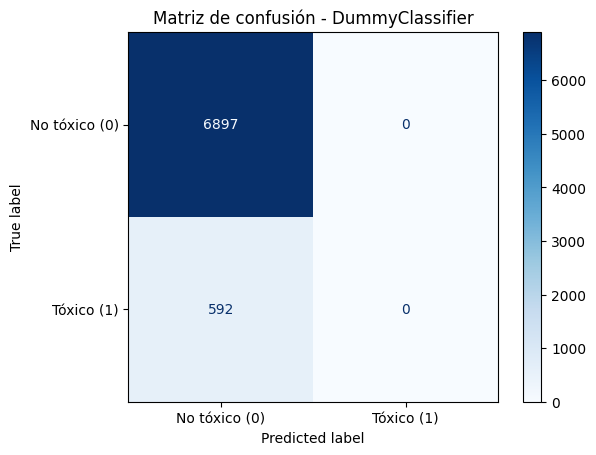

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred_baseline, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No tóxico (0)", "Tóxico (1)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - DummyClassifier")
plt.show()